# BLINKIT GROCERY SALES ANALYSIS
### Retail & Grocery Sales Analytics | Sapphire IQ

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and Jupyter Notebook  
**Dataset:** BlinkIT Grocery Data

## Project overview
This project analyzes grocery sales across products, product categories, outlet formats and outlet locations. The objective is to convert the available sales records into clear findings that can support business decisions.

## Project objectives
1. Understand the business and its sales performance.
2. Check the reliability and quality of the available information.
3. Investigate factors associated with better sales performance.
4. Present findings and practical recommendations for management.

## Analysis workflow
**Load data → Understand data → Clean data → Explore sales → Compare business segments → Summarize insights**

> Run the notebook from top to bottom. The data-loading cell expects the Excel file `BlinkIT Grocery Data.xlsx` to be available in the Colab session.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. DATA LOADING

Import the source Excel workbook into the notebook environment. The next cells load the data into a Pandas DataFrame for inspection and analysis.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving BlinkIT Grocery Data.xlsx to BlinkIT Grocery Data.xlsx


In [3]:
df = pd.read_excel("BlinkIT Grocery Data.xlsx")

df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


### 1.1 Initial dataset inspection

Review the dataset dimensions, column names and data types. This establishes what information is available and helps identify fields that may need cleaning.

In [4]:

print(df.shape)


print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (8523, 12)

Columns:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item

### 1.2 Initial data-quality checks

Check missing values and duplicate records before making changes to the dataset.

In [6]:
missing_values = df.isnull().sum()

print(missing_values)

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


In [7]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


## 2. DATA CLEANING & PREPROCESSING

A separate working copy is created so the original DataFrame remains unchanged. The following steps address missing values, inconsistent categories, duplicate rows and potential outliers.

In [9]:


df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (8523, 12)
Working Dataset: (8523, 12)


### 2.1 Missing-value assessment

Measure the number and percentage of missing values in each column. This helps determine which fields require attention.

In [10]:
# Missing value analysis

missing = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Percentage': (df_clean.isnull().sum() / len(df_clean)) * 100
})

missing = missing[missing['Missing Values'] > 0]

missing

,Missing Values,Percentage
Item Weight,1463,17.165317


### 2.2 Check product-weight consistency

Check whether each product identifier has a consistent available weight. Product-level information is used first because the same product may appear in multiple outlets.

In [11]:
# Check weight consistency for each product

weight_check = df_clean.groupby('Item Identifier')['Item Weight'].nunique()

print("Products with multiple different weights:",
      (weight_check > 1).sum())

print("Products with no available weight:",
      (weight_check == 0).sum())

Products with multiple different weights: 0
Products with no available weight: 4


### 2.3 Impute missing product weights

Fill missing weights using the available weight for the same product identifier.

In [12]:
# Fill missing weights using the same product's available weight

df_clean['Item Weight'] = (
    df_clean.groupby('Item Identifier')['Item Weight']
    .transform(lambda x: x.fillna(x.median()))
)

### 2.4 Fill any remaining missing weights

For product identifiers without an available weight, use the median weight within the corresponding item category. This retains records while using a category-level estimate.

In [13]:
# Fill remaining missing values using Item Type median

df_clean['Item Weight'] = (
    df_clean.groupby('Item Type')['Item Weight']
    .transform(lambda x: x.fillna(x.median()))
)

In [14]:
print("Remaining Missing Values:")
print(df_clean.isnull().sum())

Remaining Missing Values:
Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64


### 2.5 Standardize categorical values

The `Item Fat Content` field contains variations in capitalization and abbreviations. Map equivalent labels to consistent categories so that grouping and comparisons are reliable.

In [15]:
# Check original categories

print(df_clean['Item Fat Content'].value_counts())

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


In [16]:
# Standardize Item Fat Content

df_clean['Item Fat Content'] = (
    df_clean['Item Fat Content']
    .replace({
        'LF': 'Low Fat',
        'low fat': 'Low Fat',
        'reg': 'Regular'
    })
)

In [17]:
print(df_clean['Item Fat Content'].value_counts())

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


### 2.6 Duplicate-record check

Check whether any complete rows are repeated. Remove duplicates only if they are present.

In [18]:
# Check duplicate records

print("Total Duplicate Rows:", df_clean.duplicated().sum())

Total Duplicate Rows: 0


In [19]:
df_clean = df_clean.drop_duplicates()

### 2.7 Outlier detection using the IQR method

Use the interquartile range (IQR) to flag unusually low or high values in selected numerical columns.

**Important:** Outlier flags are not automatically errors. Sales extremes may represent genuine business activity, so the analysis identifies them without deleting them.

In [20]:
# Outlier detection using IQR

numerical_columns = [
    'Item Weight',
    'Item Visibility',
    'Sales',
    'Rating'
]

for col in numerical_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outliers:", len(outliers))


Column: Item Weight
Lower Bound: -3.3125000000000018
Upper Bound: 28.947500000000005
Outliers: 0

Column: Item Visibility
Lower Bound: -0.07440424500000001
Upper Bound: 0.195979015
Outliers: 144

Column: Sales
Lower Bound: -43.8993
Upper Bound: 323.3695
Outliers: 0

Column: Rating
Lower Bound: 3.6999999999999997
Upper Bound: 4.5
Outliers: 1931


### 2.8 Validate cleaned data

Review the resulting data types and missing-value counts to confirm the cleaning steps.

In [21]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                8523 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


### 2.9 Export the cleaned dataset

Save the cleaned records as a CSV file for reuse in subsequent analysis and reporting.

In [22]:
df_clean.to_csv(
    'BlinkIT_Cleaned_Data.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 3. EXPLORATORY DATA ANALYSIS (EDA)

EDA summarizes the overall sales picture and explores product, outlet, location and customer-rating patterns. Each visualization should be interpreted in the context of the business question it addresses.

### 3.1 Overall business performance

Calculate headline metrics such as total sales, average sales per record, sales range, average rating, unique products and outlet count.

In [23]:
# Overall Business Performance

total_sales = df_clean['Sales'].sum()

average_sales = df_clean['Sales'].mean()

maximum_sales = df_clean['Sales'].max()

minimum_sales = df_clean['Sales'].min()

average_rating = df_clean['Rating'].mean()

total_products = df_clean['Item Identifier'].nunique()

total_outlets = df_clean['Outlet Identifier'].nunique()


print("========== BLINKIT BUSINESS OVERVIEW ==========")

print(f"Total Sales: ₹{total_sales:,.2f}")

print(f"Average Sales: ₹{average_sales:,.2f}")

print(f"Maximum Sales: ₹{maximum_sales:,.2f}")

print(f"Minimum Sales: ₹{minimum_sales:,.2f}")

print(f"Average Rating: {average_rating:.2f}")

print(f"Total Unique Products: {total_products}")

print(f"Total Outlets: {total_outlets}")

========== BLINKIT BUSINESS OVERVIEW ==========
Total Sales: ₹1,201,681.49
Average Sales: ₹140.99
Maximum Sales: ₹266.89
Minimum Sales: ₹31.29
Average Rating: 3.97
Total Unique Products: 1559
Total Outlets: 10


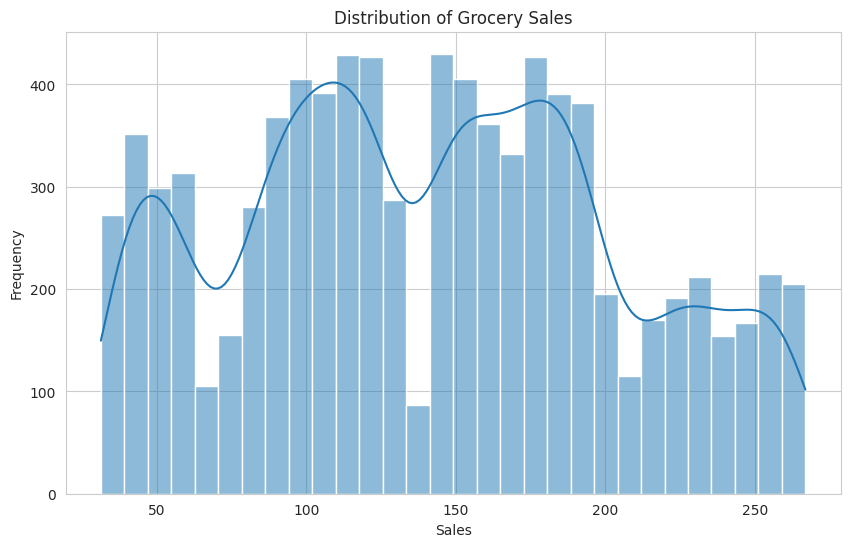

In [24]:
plt.figure(figsize=(10,6))

sns.histplot(
    df_clean['Sales'],
    bins=30,
    kde=True
)

plt.title('Distribution of Grocery Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

### 3.2 Product category performance

Aggregate sales by item category to identify categories with the largest total sales contribution.

In [25]:
category_sales = (
    df_clean.groupby('Item Type')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


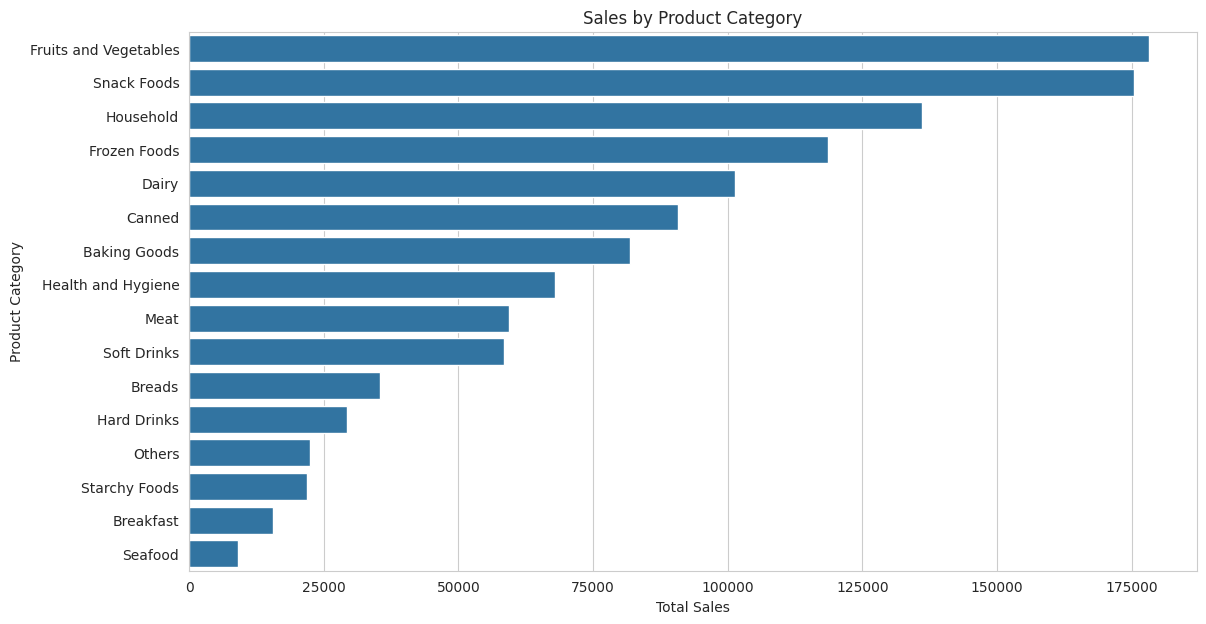

In [26]:
plt.figure(figsize=(13,7))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title('Sales by Product Category')
plt.xlabel('Total Sales')
plt.ylabel('Product Category')

plt.show()

In [27]:
top_5_categories = category_sales.head(5)

print("Top 5 Product Categories:")
print(top_5_categories)

Top 5 Product Categories:
Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Name: Sales, dtype: float64


### 3.3 Sales by item fat content

Compare total and average sales for the standardized fat-content groups. Total sales measure overall contribution; average sales measure sales per record.

In [28]:
fat_sales = df_clean.groupby(
    'Item Fat Content'
)['Sales'].sum()

print(fat_sales)

Item Fat Content
Low Fat    776319.6884
Regular    425361.8044
Name: Sales, dtype: float64


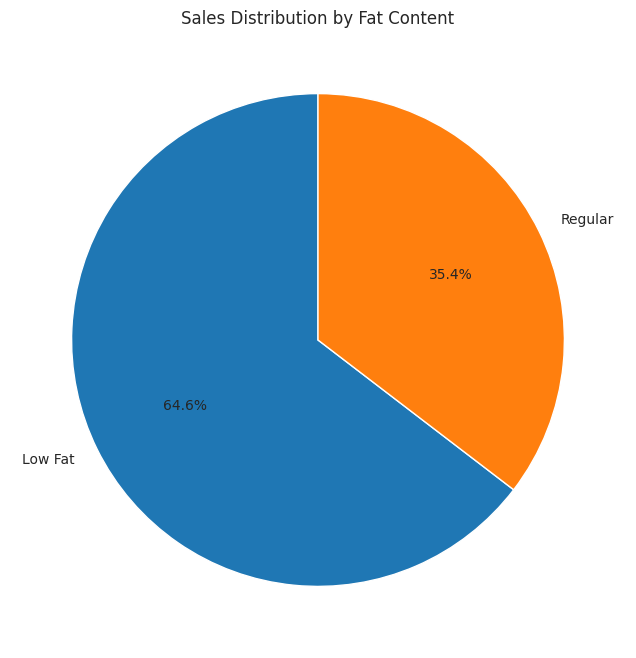

In [29]:
plt.figure(figsize=(8,8))

plt.pie(
    fat_sales,
    labels=fat_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales Distribution by Fat Content')

plt.show()

In [30]:
fat_avg_sales = df_clean.groupby(
    'Item Fat Content'
)['Sales'].mean()

print(fat_avg_sales)

Item Fat Content
Low Fat    140.71410
Regular    141.50426
Name: Sales, dtype: float64


### 3.4 Outlet-level sales performance

Compare total sales across outlet identifiers and identify the outlet with the highest recorded sales.

In [31]:
outlet_sales = (
    df_clean.groupby('Outlet Identifier')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(outlet_sales)

Outlet Identifier
OUT035    133103.9070
OUT046    132113.3698
OUT013    131809.0156
OUT018    131477.7764
OUT045    130942.7802
OUT027    130714.6746
OUT049    130476.8598
OUT017    129103.9604
OUT010     78131.5666
OUT019     73807.5824
Name: Sales, dtype: float64


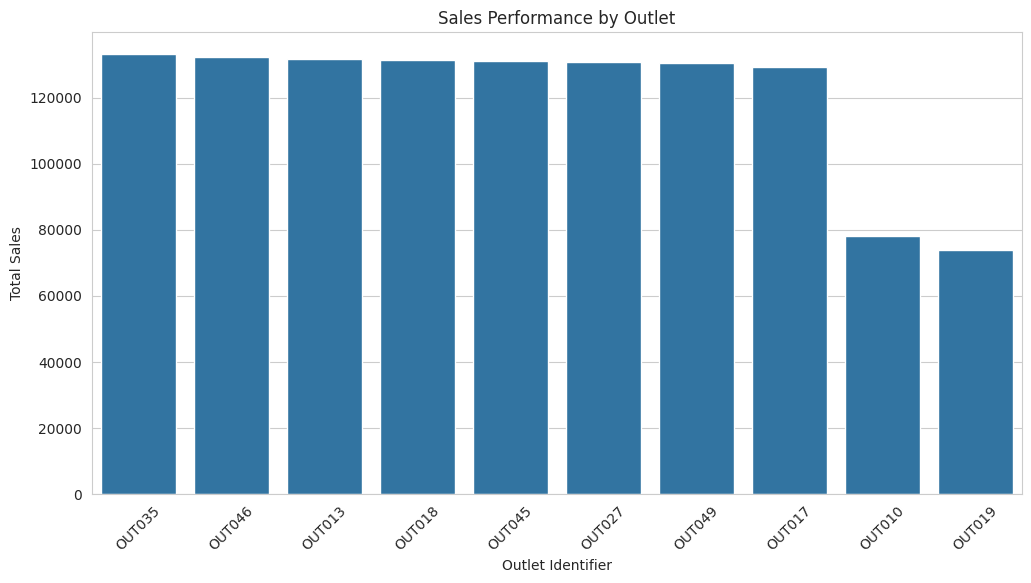

In [32]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=outlet_sales.index,
    y=outlet_sales.values
)

plt.title('Sales Performance by Outlet')
plt.xlabel('Outlet Identifier')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.show()

In [33]:
best_outlet = outlet_sales.idxmax()

print("Best Performing Outlet:", best_outlet)

print("Sales Generated:", outlet_sales.max())

Best Performing Outlet: OUT035
Sales Generated: 133103.907


### 3.5 Sales by outlet location tier

Compare total and average sales across Tier 1, Tier 2 and Tier 3 locations. These measures answer different questions and should be interpreted separately.

In [34]:
location_sales = (
    df_clean.groupby('Outlet Location Type')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(location_sales)

Outlet Location Type
Tier 3    472133.0332
Tier 2    393150.6476
Tier 1    336397.8120
Name: Sales, dtype: float64


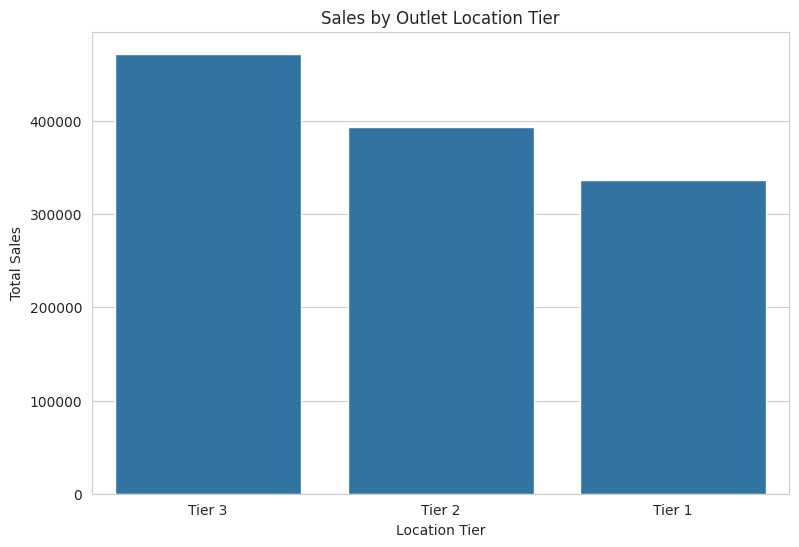

In [35]:
plt.figure(figsize=(9,6))

sns.barplot(
    x=location_sales.index,
    y=location_sales.values
)

plt.title('Sales by Outlet Location Tier')
plt.xlabel('Location Tier')
plt.ylabel('Total Sales')

plt.show()

In [36]:
location_avg = df_clean.groupby(
    'Outlet Location Type'
)['Sales'].mean()

print(location_avg)

Outlet Location Type
Tier 1    140.870106
Tier 2    141.167198
Tier 3    140.935234
Name: Sales, dtype: float64


### 3.6 Sales by outlet size

Compare sales across outlet-size categories. Differences in total sales may partly reflect differences in the number of records represented in each group.

In [37]:
size_sales = (
    df_clean.groupby('Outlet Size')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(size_sales)

Outlet Size
Medium    507895.7364
Small     444794.1704
High      248991.5860
Name: Sales, dtype: float64


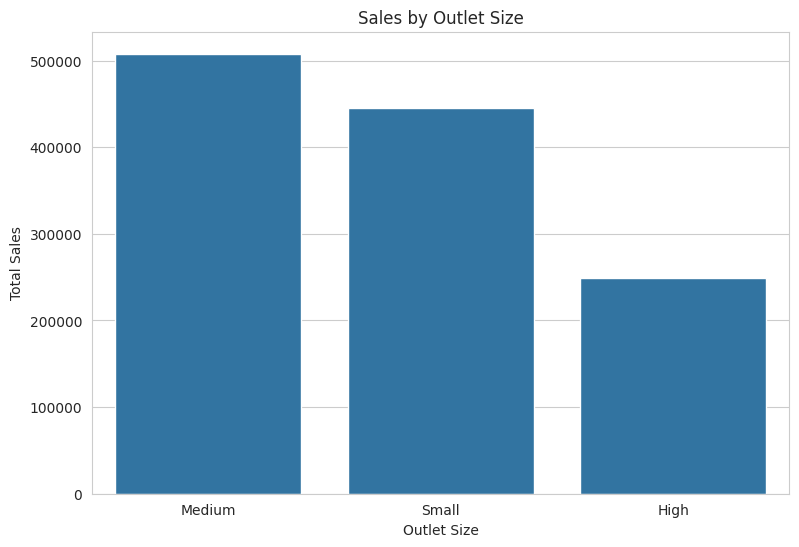

In [38]:
plt.figure(figsize=(9,6))

sns.barplot(
    x=size_sales.index,
    y=size_sales.values
)

plt.title('Sales by Outlet Size')
plt.xlabel('Outlet Size')
plt.ylabel('Total Sales')

plt.show()

In [39]:
size_avg = df_clean.groupby(
    'Outlet Size'
)['Sales'].mean()

print(size_avg)

Outlet Size
High      142.037414
Medium    139.877647
Small     141.699322
Name: Sales, dtype: float64


### 3.7 Customer ratings

Examine the overall rating distribution and compare average ratings across product categories.

In [40]:
average_rating = df_clean['Rating'].mean()

print("Average Customer Rating:", round(average_rating, 2))

Average Customer Rating: 3.97


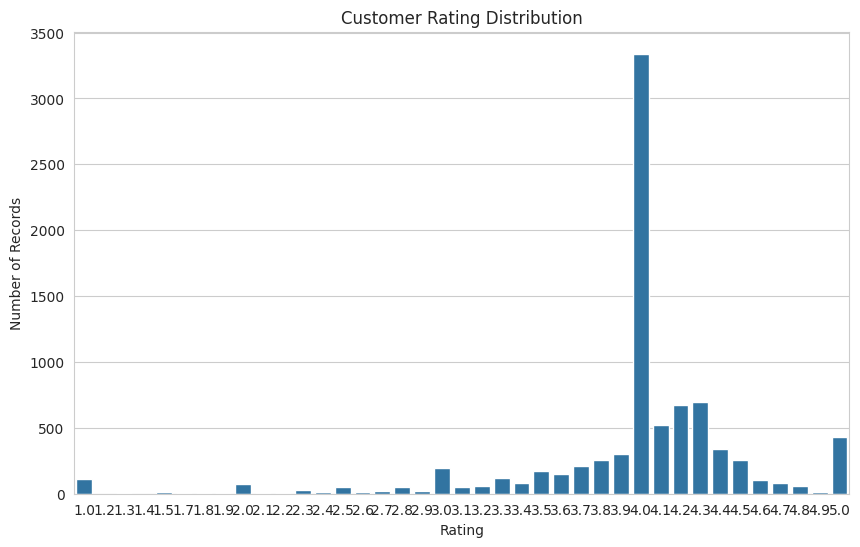

In [41]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    x='Rating'
)

plt.title('Customer Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Records')

plt.show()

In [42]:
category_rating = (
    df_clean.groupby('Item Type')['Rating']
    .mean()
    .sort_values(ascending=False)
)

print(category_rating)

Item Type
Meat                     4.023059
Household                3.998681
Canned                   3.994299
Health and Hygiene       3.986154
Baking Goods             3.983025
Frozen Foods             3.971145
Dairy                    3.965836
Seafood                  3.959375
Fruits and Vegetables    3.956169
Others                   3.954438
Snack Foods              3.948917
Breakfast                3.932727
Soft Drinks              3.920674
Starchy Foods            3.920270
Hard Drinks              3.907477
Breads                   3.881275
Name: Rating, dtype: float64


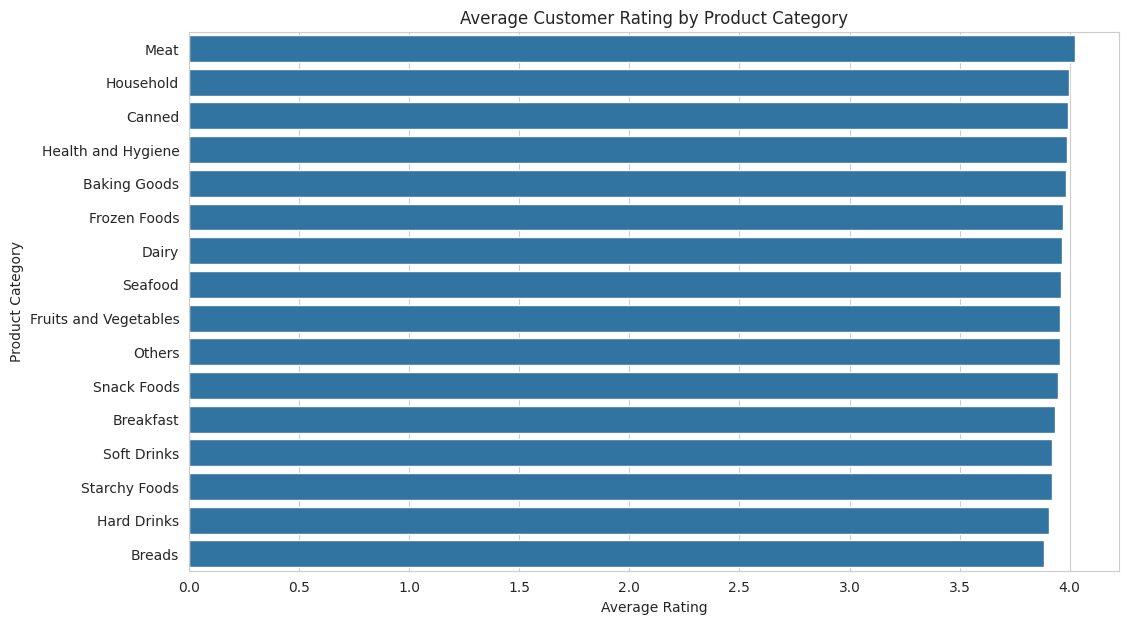

In [43]:
plt.figure(figsize=(12,7))

sns.barplot(
    x=category_rating.values,
    y=category_rating.index
)

plt.title('Average Customer Rating by Product Category')
plt.xlabel('Average Rating')
plt.ylabel('Product Category')

plt.show()

### 3.8 Product visibility and sales

Use a scatter plot and correlation coefficient to assess whether item visibility has a linear association with sales. Correlation does not establish causation.

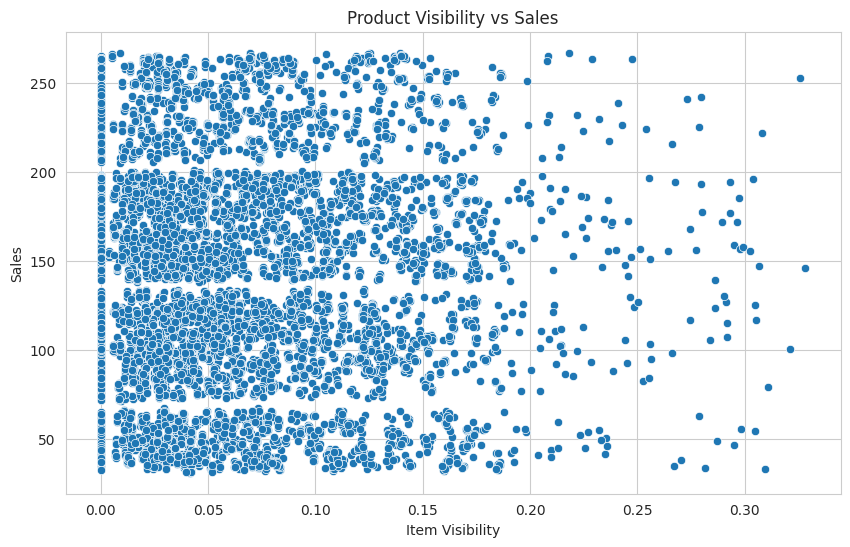

In [44]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_clean,
    x='Item Visibility',
    y='Sales'
)

plt.title('Product Visibility vs Sales')
plt.xlabel('Item Visibility')
plt.ylabel('Sales')

plt.show()

In [45]:
correlation = df_clean[
    ['Item Visibility', 'Sales']
].corr()

print(correlation)

                 Item Visibility     Sales
Item Visibility         1.000000 -0.001315
Sales                  -0.001315  1.000000


### 3.9 Correlation among numerical variables

The heatmap summarizes pairwise linear correlations among item weight, item visibility, sales and rating. Interpret the values as associations, not causal effects.

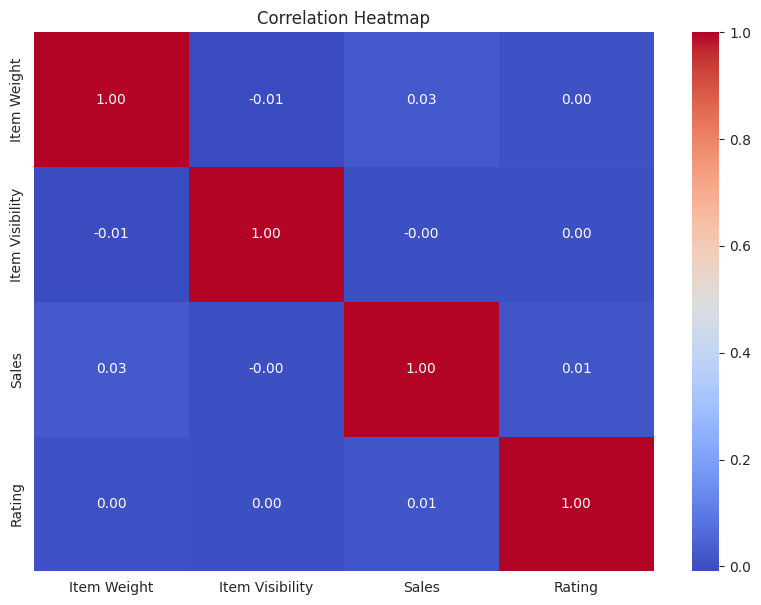

In [46]:
plt.figure(figsize=(10,7))

correlation_matrix = df_clean[
    ['Item Weight',
     'Item Visibility',
     'Sales',
     'Rating']
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

## 4. ADVANCED BUSINESS ANALYSIS

This section compares business dimensions to understand how sales vary across outlet characteristics and product segments.

### 4.1 Outlet establishment year

Compare total and average sales by outlet establishment year. The results describe differences across establishment cohorts; they do not by themselves show that outlet age causes higher or lower sales.

In [47]:
establishment_sales = (
    df_clean.groupby('Outlet Establishment Year')['Sales']
    .sum()
    .sort_index()
)

print(establishment_sales)

Outlet Establishment Year
2011     78131.5666
2012    130476.8598
2014    131809.0156
2015    130942.7802
2016    132113.3698
2017    133103.9070
2018    204522.2570
2020    129103.9604
2022    131477.7764
Name: Sales, dtype: float64


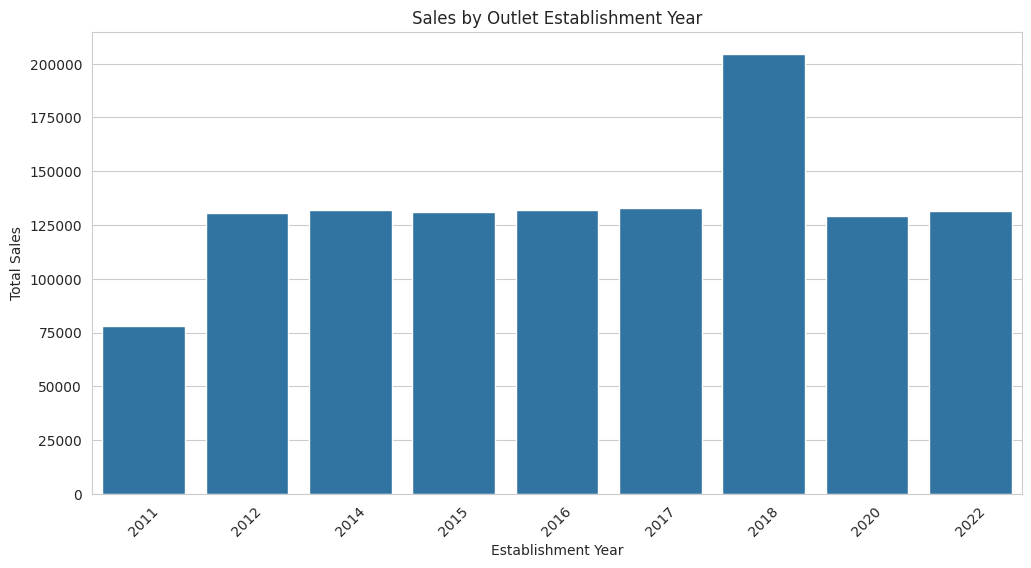

In [48]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=establishment_sales.index,
    y=establishment_sales.values
)

plt.title('Sales by Outlet Establishment Year')
plt.xlabel('Establishment Year')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.show()

In [49]:
establishment_avg = (
    df_clean.groupby('Outlet Establishment Year')['Sales']
    .mean()
)

print(establishment_avg)

Outlet Establishment Year
2011    140.777597
2012    140.297699
2014    141.425982
2015    140.950248
2016    142.057387
2017    143.122481
2018    139.796485
2020    139.421124
2022    141.678638
Name: Sales, dtype: float64


### 4.2 Outlet type performance

Compare total sales, average sales and record counts across outlet formats. Considering all three measures helps avoid interpreting total sales alone as operational efficiency.

In [50]:
outlet_type_sales = (
    df_clean.groupby('Outlet Type')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(outlet_type_sales)

Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


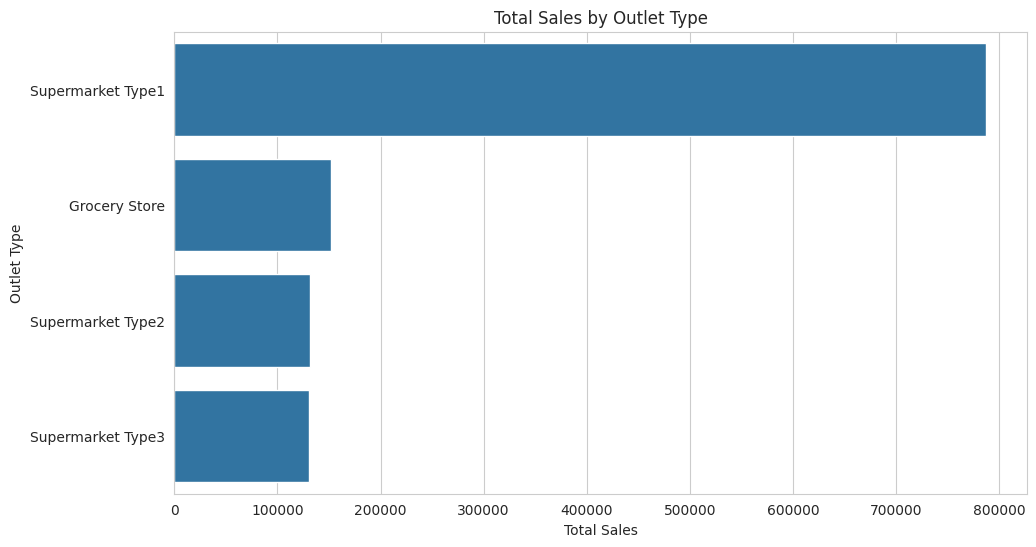

In [51]:
plt.figure(figsize=(11,6))

sns.barplot(
    x=outlet_type_sales.values,
    y=outlet_type_sales.index
)

plt.title('Total Sales by Outlet Type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Type')

plt.show()

In [52]:
outlet_type_avg = (
    df_clean.groupby('Outlet Type')['Sales']
    .mean()
)

print(outlet_type_avg)

Outlet Type
Grocery Store        140.294690
Supermarket Type1    141.213895
Supermarket Type2    141.678638
Supermarket Type3    139.801791
Name: Sales, dtype: float64


In [53]:
outlet_type_records = (
    df_clean.groupby('Outlet Type')
    .size()
    .sort_values(ascending=False)
)

print(outlet_type_records)

Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
dtype: int64


### 4.3 Product category by outlet type

Create a category-by-outlet-type sales matrix to identify which categories contribute most within each outlet format.

In [54]:
category_outlet = pd.pivot_table(
    df_clean,
    values='Sales',
    index='Item Type',
    columns='Outlet Type',
    aggfunc='sum'
)

category_outlet

Outlet Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Item Type,,,,
Baking Goods,10747.2358,53665.4614,8594.2014,8887.8378
Breads,4832.9448,22490.8084,3539.4032,4515.9634
Breakfast,2793.5128,9632.6468,1552.6140,1617.9230
Canned,10079.8990,59649.3094,10852.4710,10125.0496
Dairy,13539.3398,67179.6940,10638.9446,9918.4832
Frozen Foods,13750.4410,79348.3770,13253.7174,12206.3460
Fruits and Vegetables,21423.4146,117431.9880,18967.2918,20301.3866
Hard Drinks,2812.5444,19610.7566,3609.1194,3302.2602
Health and Hygiene,8964.0234,44050.7466,7339.9238,7671.1450


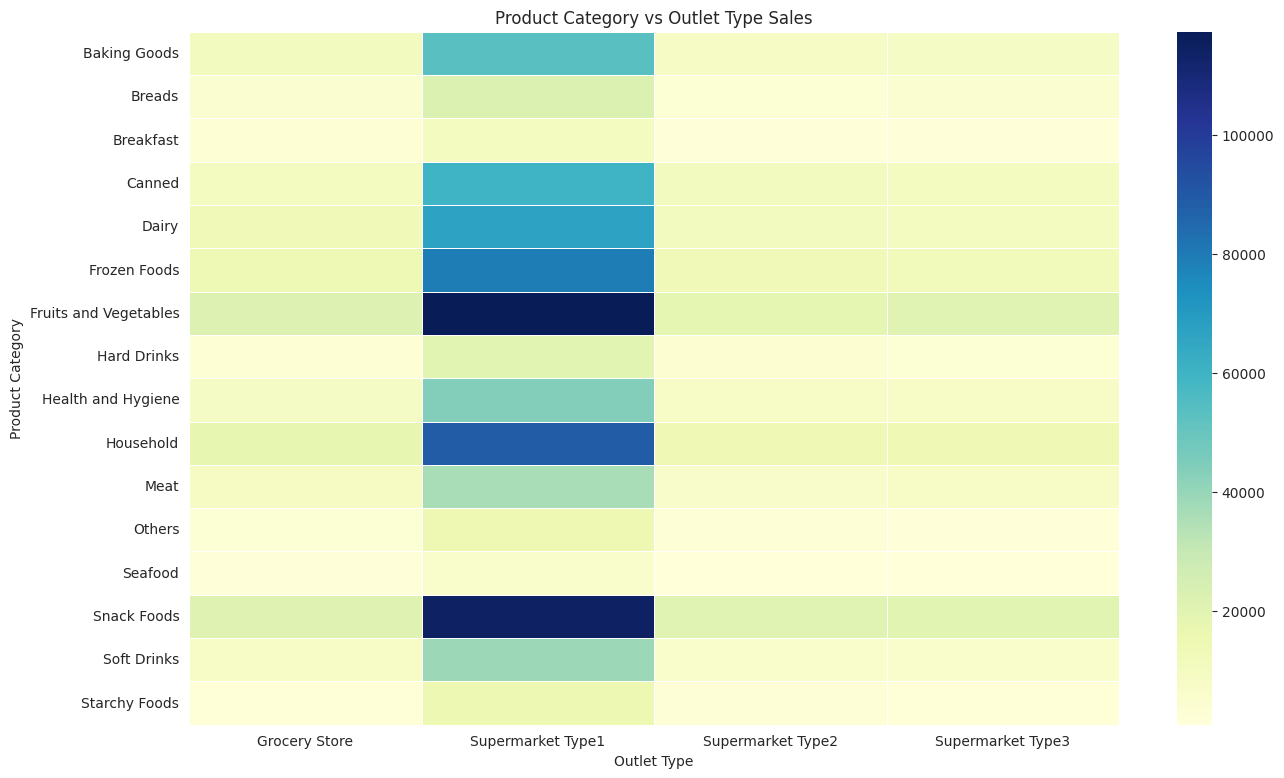

In [55]:
plt.figure(figsize=(15,9))

sns.heatmap(
    category_outlet,
    annot=False,
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Product Category vs Outlet Type Sales')
plt.xlabel('Outlet Type')
plt.ylabel('Product Category')

plt.show()

In [56]:
best_category = category_outlet.idxmax()

print("Best Performing Category by Outlet Type:")
print(best_category)

Best Performing Category by Outlet Type:
Outlet Type
Grocery Store        Fruits and Vegetables
Supermarket Type1    Fruits and Vegetables
Supermarket Type2              Snack Foods
Supermarket Type3    Fruits and Vegetables
dtype: object


### 4.4 Outlet location and size

Compare total sales across combinations of location tier and outlet size. This can help identify segment combinations for further investigation.

In [57]:
location_size = pd.pivot_table(
    df_clean,
    values='Sales',
    index='Outlet Location Type',
    columns='Outlet Size',
    aggfunc='sum'
)

location_size

Outlet Size,High,Medium,Small
Outlet Location Type,,,
Tier 1,NaN,130476.8598,205920.9522
Tier 2,84612.4474,78048.3144,230489.8858
Tier 3,164379.1386,299370.5622,8383.3324


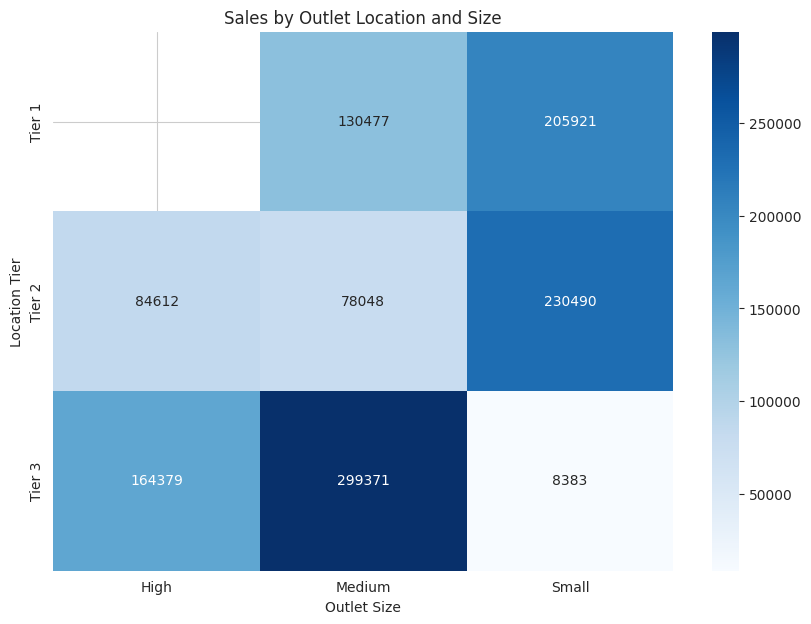

In [58]:
plt.figure(figsize=(10,7))

sns.heatmap(
    location_size,
    annot=True,
    fmt='.0f',
    cmap='Blues'
)

plt.title('Sales by Outlet Location and Size')
plt.xlabel('Outlet Size')
plt.ylabel('Location Tier')

plt.show()

### 4.5 Product weight and sales

Explore the relationship between item weight and sales, then compare sales across weight bands. Product category and price may also influence observed differences.

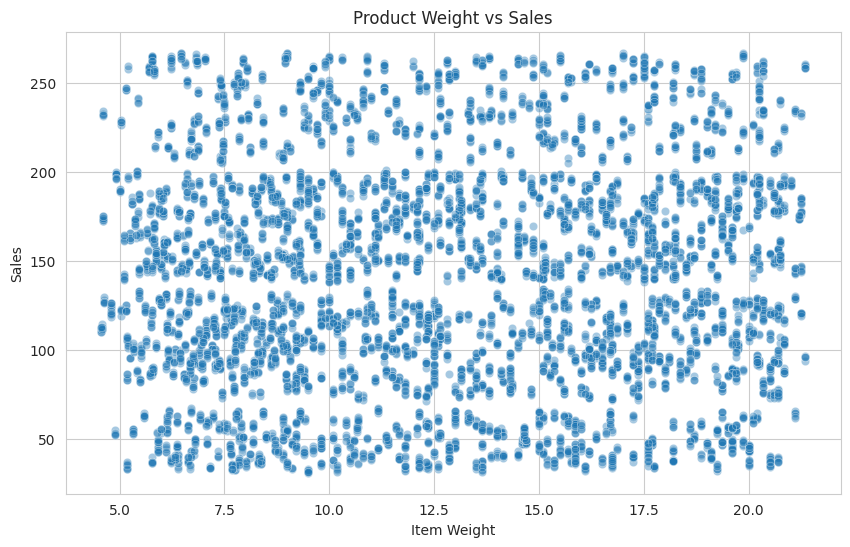

In [59]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_clean,
    x='Item Weight',
    y='Sales',
    alpha=0.4
)

plt.title('Product Weight vs Sales')
plt.xlabel('Item Weight')
plt.ylabel('Sales')

plt.show()

In [60]:
weight_correlation = df_clean[
    ['Item Weight', 'Sales']
].corr()

print(weight_correlation)

             Item Weight    Sales
Item Weight      1.00000  0.02597
Sales            0.02597  1.00000


In [61]:
df_clean['Weight Category'] = pd.cut(
    df_clean['Item Weight'],
    bins=[0, 5, 10, 15, 20, float('inf')],
    labels=['0-5', '5-10', '10-15', '15-20', '20+']
)

In [62]:
weight_sales = (
    df_clean.groupby('Weight Category', observed=True)['Sales']
    .sum()
)

print(weight_sales)

Weight Category
0-5        9022.5272
5-10     395584.0326
10-15    343952.8596
15-20    370974.2062
20+       82147.8672
Name: Sales, dtype: float64


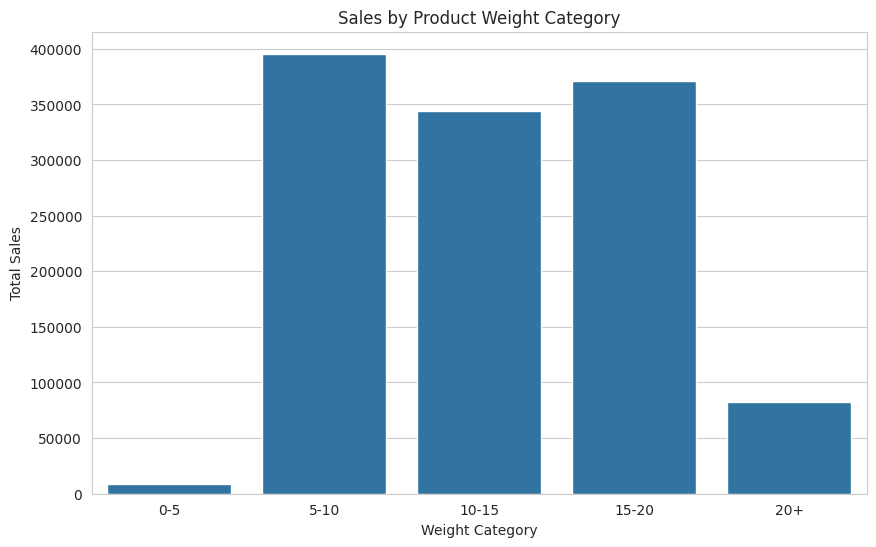

In [63]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=weight_sales.index,
    y=weight_sales.values
)

plt.title('Sales by Product Weight Category')
plt.xlabel('Weight Category')
plt.ylabel('Total Sales')

plt.show()

### 4.6 Fat content by outlet type

Compare sales for Low Fat and Regular products across outlet formats to understand how the two product groups contribute within each format.

In [64]:
fat_outlet = pd.pivot_table(
    df_clean,
    values='Sales',
    index='Item Fat Content',
    columns='Outlet Type',
    aggfunc='sum'
)

fat_outlet

Outlet Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Item Fat Content,,,,
Low Fat,99814.367,507886.3014,84844.6090,83774.4110
Regular,52124.782,279663.5914,46633.1674,46940.2636


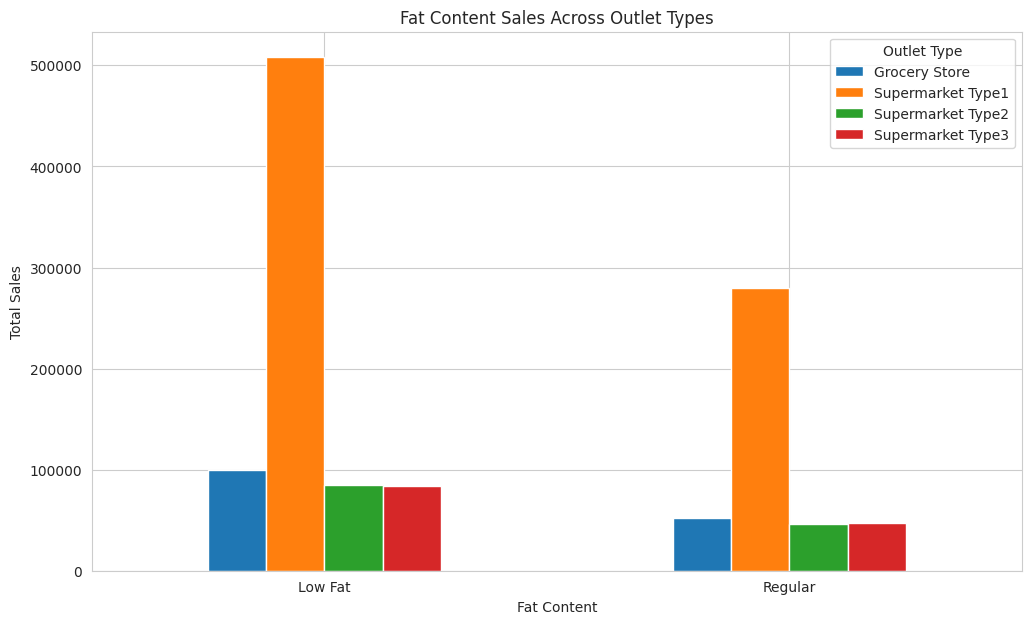

In [65]:
fat_outlet.plot(
    kind='bar',
    figsize=(12,7)
)

plt.title('Fat Content Sales Across Outlet Types')
plt.xlabel('Fat Content')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.legend(title='Outlet Type')

plt.show()

### 4.7 Category sales contribution

Calculate each product category's share of total sales and visualize the leading contributors.

In [66]:
category_contribution = (
    df_clean.groupby('Item Type')['Sales']
    .sum()
    .sort_values(ascending=False)
)

category_percentage = (
    category_contribution / category_contribution.sum()
) * 100

print(category_percentage)

Item Type
Fruits and Vegetables    14.822903
Snack Foods              14.599037
Household                11.315521
Frozen Foods              9.866082
Dairy                     8.427896
Canned                    7.548317
Baking Goods              6.815012
Health and Hygiene        5.660888
Meat                      4.947223
Soft Drinks               4.869357
Breads                    2.944135
Hard Drinks               2.441136
Others                    1.868373
Starchy Foods             1.820784
Breakfast                 1.297906
Seafood                   0.755431
Name: Sales, dtype: float64


### 4.8 Outlet performance summary

Build an outlet-level scorecard containing total sales, average sales, record count and average rating. Review top and bottom outlets in context; outlet size, format and location may affect comparisons.

In [67]:
outlet_performance = df_clean.groupby(
    'Outlet Identifier'
).agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Total_Records=('Sales', 'count'),
    Average_Rating=('Rating', 'mean')
)

outlet_performance = outlet_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

outlet_performance

,Total_Sales,Average_Sales,Total_Records,Average_Rating
Outlet Identifier,,,,
OUT035,133103.9070,143.122481,930,3.944516
OUT046,132113.3698,142.057387,930,3.958387
OUT013,131809.0156,141.425982,932,3.949571
OUT018,131477.7764,141.678638,928,3.971228
OUT045,130942.7802,140.950248,929,3.959957
OUT027,130714.6746,139.801791,935,3.952941
OUT049,130476.8598,140.297699,930,3.985484
OUT017,129103.9604,139.421124,926,3.981641
OUT010,78131.5666,140.777597,555,3.977117


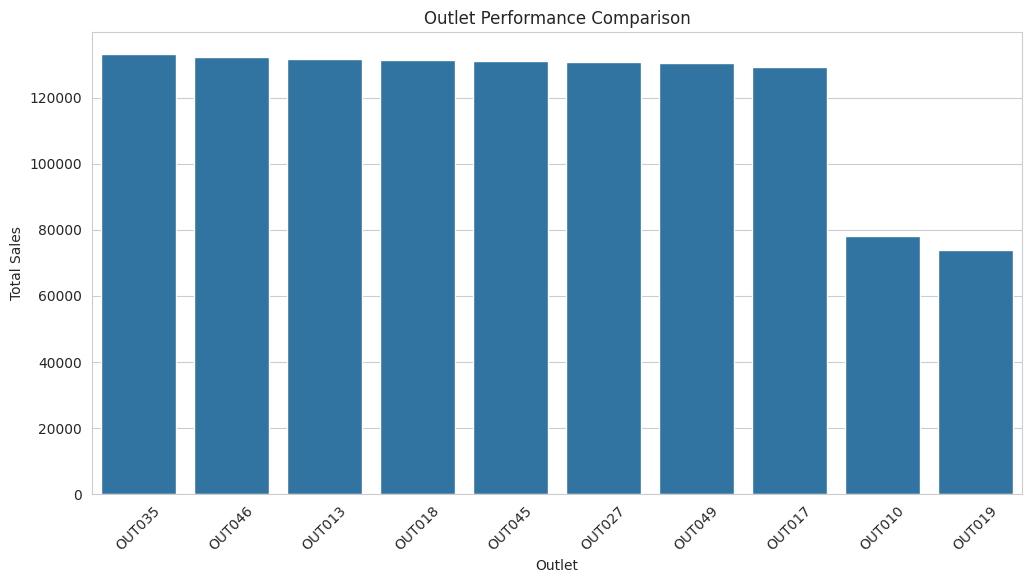

In [68]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=outlet_performance.reset_index(),
    x='Outlet Identifier',
    y='Total_Sales'
)

plt.title('Outlet Performance Comparison')
plt.xlabel('Outlet')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.show()

In [69]:
print("TOP 3 OUTLETS")
display(outlet_performance.head(3))

print("BOTTOM 3 OUTLETS")
display(outlet_performance.tail(3))

TOP 3 OUTLETS


,Total_Sales,Average_Sales,Total_Records,Average_Rating
Outlet Identifier,,,,
OUT035,133103.9070,143.122481,930,3.944516
OUT046,132113.3698,142.057387,930,3.958387
OUT013,131809.0156,141.425982,932,3.949571


BOTTOM 3 OUTLETS


,Total_Sales,Average_Sales,Total_Records,Average_Rating
Outlet Identifier,,,,
OUT017,129103.9604,139.421124,926,3.981641
OUT010,78131.5666,140.777597,555,3.977117
OUT019,73807.5824,139.787088,528,3.995076


## 5. CONSOLIDATED BUSINESS KPIs

Bring the headline metrics together in one table for convenient reference in the final report.

In [70]:
business_kpis = pd.DataFrame({
    'Metric': [
        'Total Sales',
        'Average Sales',
        'Total Products',
        'Total Outlets',
        'Average Rating',
        'Total Product Categories'
    ],

    'Value': [
        df_clean['Sales'].sum(),
        df_clean['Sales'].mean(),
        df_clean['Item Identifier'].nunique(),
        df_clean['Outlet Identifier'].nunique(),
        df_clean['Rating'].mean(),
        df_clean['Item Type'].nunique()
    ]
})

business_kpis

,Metric,Value
0,Total Sales,1.201681e+06
1,Average Sales,1.409928e+02
2,Total Products,1.559000e+03
3,Total Outlets,1.000000e+01
4,Average Rating,3.965857e+00
5,Total Product Categories,1.600000e+01


## 6. KEY BUSINESS INSIGHTS & RECOMMENDATIONS

The table below consolidates the main business areas, findings and suggested actions. Before submission, verify that each statement matches the actual outputs generated by the notebook.

Recommendations should be treated as opportunities for further investigation, not as proof of cause and effect.

In [71]:
business_insights = pd.DataFrame({

    'Business Area': [
        'Product Category',
        'Outlet Performance',
        'Outlet Type',
        'Location',
        'Fat Content',
        'Product Visibility'
    ],

    'Key Finding': [
        'Fruits and Vegetables generate highest sales',
        'OUT035 generates highest outlet sales',
        'Supermarket Type 1 leads sales',
        'Tier 3 contributes highest sales',
        'Low Fat products contribute more sales',
        'Almost zero linear correlation with sales'
    ],

    'Recommendation': [
        'Maintain availability of high-demand categories',
        'Investigate successful outlet practices',
        'Study successful supermarket operations',
        'Optimize location-specific inventory',
        'Monitor demand for both fat categories',
        'Investigate other factors influencing sales'
    ]

})

display(business_insights)

,Business Area,Key Finding,Recommendation
0,Product Category,Fruits and Vegetables generate highest sales,Maintain availability of high-demand categories
1,Outlet Performance,OUT035 generates highest outlet sales,Investigate successful outlet practices
2,Outlet Type,Supermarket Type 1 leads sales,Study successful supermarket operations
3,Location,Tier 3 contributes highest sales,Optimize location-specific inventory
4,Fat Content,Low Fat products contribute more sales,Monitor demand for both fat categories
5,Product Visibility,Almost zero linear correlation with sales,Investigate other factors influencing sales


## 7. PROJECT CONCLUSION

This notebook follows the project workflow of organizing and cleaning the data, exploring sales patterns, comparing products and outlets, and summarizing business implications.

The analysis provides descriptive evidence about product-category contributions, outlet performance, location segments, customer ratings and selected numerical relationships. Management can use these findings as a starting point for reviewing product assortment, inventory planning and outlet-level performance.

### Limitations
- The dataset contains sales records but does not provide all possible drivers of business performance, such as promotion exposure, operating costs, stock-outs or local competition.
- Associations and group differences do not establish causation.
- Imputed item weights are estimates and should be interpreted accordingly.
- Total sales and average sales per record measure different aspects of performance.
